# Tracking latency: SubjectCamera motion to quad update on screen

The workflow tracks the SubjectCamera with the TrackCamera and draws a black quad on the screen so that, seen from
the SubjectCamera, the quad stays centred and the same size. This notebook estimates the latency of that loop:
after the SubjectCamera moves, how long it takes for the quad on the screen to follow.

## Measurement principle

Everything is measured in the SubjectCamera video. Two things are visible on the screen: the black quad, which the
workflow moves, and the aruco marker, which is fixed on the screen. Both lie on the screen plane, so in a given
frame they are seen at the same scale and their image positions can be compared directly:

- The marker's position in the image tells where the camera is pointing on the screen *right now*. Its negative,
  `camera = -marker`, follows the camera's motion across the screen with no latency (in image pixels).
- The quad's position *relative to the marker*, `quad - marker`, is where the workflow has drawn the quad on the
  screen. If the loop had zero latency the quad would always sit where the camera is pointing; with latency `L`
  it sits where the camera was pointing `L` earlier: `quad(t) - marker(t) ≈ camera(t - L) + constant`.

The latency is therefore the lag `L` that best aligns the quad trajectory with the delayed camera trajectory. It is
estimated by scanning `L` and minimising the residual, and cross-checked with a velocity cross-correlation.

The estimate covers the whole loop: TrackCamera exposure and readout, marker detection and pose estimation, quad
rendering, the display, and the SubjectCamera exposure that observes the result.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import swc.aeon.io.api as aeon
from swc.aeon.io.video import frames

from session_io import declare_experiment, find_device_schema, load_camera

## Dataset location and experiment

Frames logged before `StartCameras` are not trigger-driven and are dropped.

In [2]:
root = Path("../temp_data/sub-Plimbo/ses-001_date-2026-10-15T15-25-50")
experiment = declare_experiment(find_device_schema(root))
board = experiment.BehaviorBoard

cameras_started = aeon.load(root, board.StartCameras).index.min()
subject_video = load_camera(root, experiment.SubjectCamera)
subject_video = subject_video[subject_video.index >= cameras_started]
seconds = np.array(aeon.to_seconds(subject_video.index))
seconds -= seconds[0]
frame_interval = np.median(np.diff(seconds))
print(f"{len(subject_video)} frames over {seconds[-1]:.1f} s, frame interval {frame_interval * 1e3:.2f} ms")

4872 frames over 32.5 s, frame interval 6.66 ms


## Detecting the quad and the marker in each frame

The marker is detected with OpenCV's aruco detector (the on-screen marker is id 2 of `DICT_ARUCO_ORIGINAL`, generated
from `markers/`), with sub-pixel corner refinement. The quad is the solid dark square on the bright screen: dark
regions are segmented with an Otsu threshold and kept if they are convex quadrilaterals, completely filled (which
excludes the marker, whose cells are white), and do not touch the image border (which excludes the room beyond the
screen edge).

In [3]:
aruco_detector_params = cv2.aruco.DetectorParameters()
aruco_detector_params.cornerRefinementMethod = cv2.aruco.CORNER_REFINE_SUBPIX
aruco_detector = cv2.aruco.ArucoDetector(cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_ARUCO_ORIGINAL), aruco_detector_params)
MARKER_ID = 2


def detect_marker(gray):
    """Centre and side length (px) of the on-screen aruco marker, or None."""
    corners, ids, _ = aruco_detector.detectMarkers(gray)
    if ids is None or MARKER_ID not in ids:
        return None
    c = corners[list(ids.ravel()).index(MARKER_ID)][0]
    return {"marker_x": c[:, 0].mean(), "marker_y": c[:, 1].mean(), "marker_side": np.linalg.norm(np.roll(c, -1, axis=0) - c, axis=1).mean()}


def detect_quad(gray, min_area=400):
    """Centroid and area (px) of the largest solid dark quadrilateral on the screen, or None."""
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    contours, hierarchy = cv2.findContours(binary, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    height, width = gray.shape
    candidates = []
    for i, contour in enumerate(contours):
        if hierarchy[0][i][3] != -1:  # inner contour (a hole in a dark region)
            continue
        area = cv2.contourArea(contour)
        if area < min_area or area > 0.25 * height * width:
            continue
        x, y, w, h = cv2.boundingRect(contour)
        if x <= 1 or y <= 1 or x + w >= width - 1 or y + h >= height - 1:  # touches the image border
            continue
        if area / cv2.contourArea(cv2.convexHull(contour)) < 0.9:  # not convex
            continue
        if len(cv2.approxPolyDP(contour, 0.04 * cv2.arcLength(contour, True), True)) != 4:  # not a quadrilateral
            continue
        mask = np.zeros_like(binary)
        cv2.drawContours(mask, [contour], -1, 255, -1)
        if (binary[mask > 0] > 0).mean() < 0.97:  # has bright pixels inside (the marker)
            continue
        m = cv2.moments(contour)
        candidates.append({"quad_x": m["m10"] / m["m00"], "quad_y": m["m01"] / m["m00"], "quad_area": area})
    return max(candidates, key=lambda c: c["quad_area"]) if candidates else None


def detect(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return {**(detect_marker(gray) or {}), **(detect_quad(gray) or {})}

In [4]:
tracks = pd.DataFrame([detect(image) for image in frames(subject_video)], index=subject_video.index)
tracks["seconds"] = seconds
print(f"marker detected in {tracks['marker_x'].notna().mean():.1%} of frames, quad in {tracks['quad_x'].notna().mean():.1%}")
tracks.head()

marker detected in 76.7% of frames, quad in 97.4%


,marker_x,marker_y,marker_side,quad_x,quad_y,quad_area,seconds
time,,,,,,,
1904-02-18 23:31:51.137600+00:00,556.264954,309.693604,103.453682,NaN,NaN,NaN,0.000000
1904-02-18 23:31:51.144224+00:00,556.259094,309.741913,103.399254,NaN,NaN,NaN,0.006624
1904-02-18 23:31:51.150912+00:00,556.273438,309.654449,103.443542,NaN,NaN,NaN,0.013312
1904-02-18 23:31:51.157568+00:00,556.300293,309.323273,103.394501,383.708889,256.108431,12375.0,0.019968
1904-02-18 23:31:51.164224+00:00,556.274170,309.341614,103.420570,383.144204,256.298557,12743.5,0.026624


Text(0.5, 1.0, 'frame 3255')

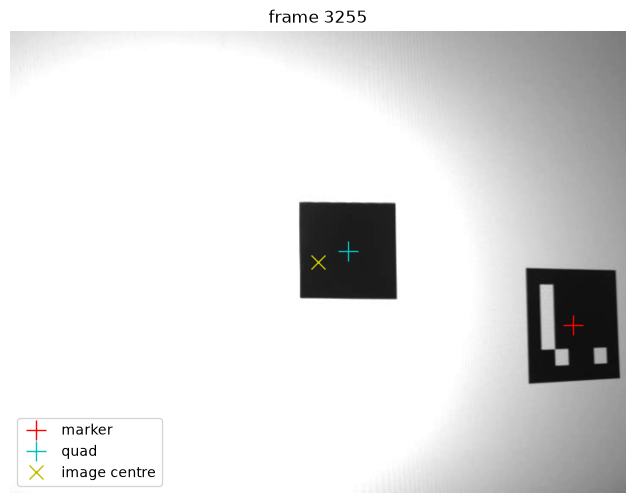

In [5]:
# Overlay the detections on a frame where both are visible, as a sanity check
example = tracks.index[tracks[["marker_x", "quad_x"]].notna().all(axis=1)][len(tracks) // 2]
image = next(frames(subject_video.loc[[example]]))
row = tracks.loc[example]
plt.figure(figsize=(8, 6))
plt.imshow(image[:, :, ::-1])
plt.plot(row.marker_x, row.marker_y, "r+", markersize=14, label="marker")
plt.plot(row.quad_x, row.quad_y, "c+", markersize=14, label="quad")
plt.plot(image.shape[1] / 2, image.shape[0] / 2, "yx", markersize=10, label="image centre")
plt.legend(loc="lower left")
plt.axis("off")
plt.title(f"frame {int(subject_video.loc[example, '_frame'])}")

## Camera and quad trajectories on the screen

`camera` is the camera's pointing position on the screen relative to the fixed marker, and `quad` is the quad's
position on the screen relative to the marker, both in SubjectCamera pixels. Frames where the marker is out of view
(mostly during large excursions) are left blank. Note that the quad trajectory is noisier than the camera
trajectory: that is jitter in the tracking loop itself, since the camera trajectory comes from the marker, which does
not move.

3617 frames with both marker and quad


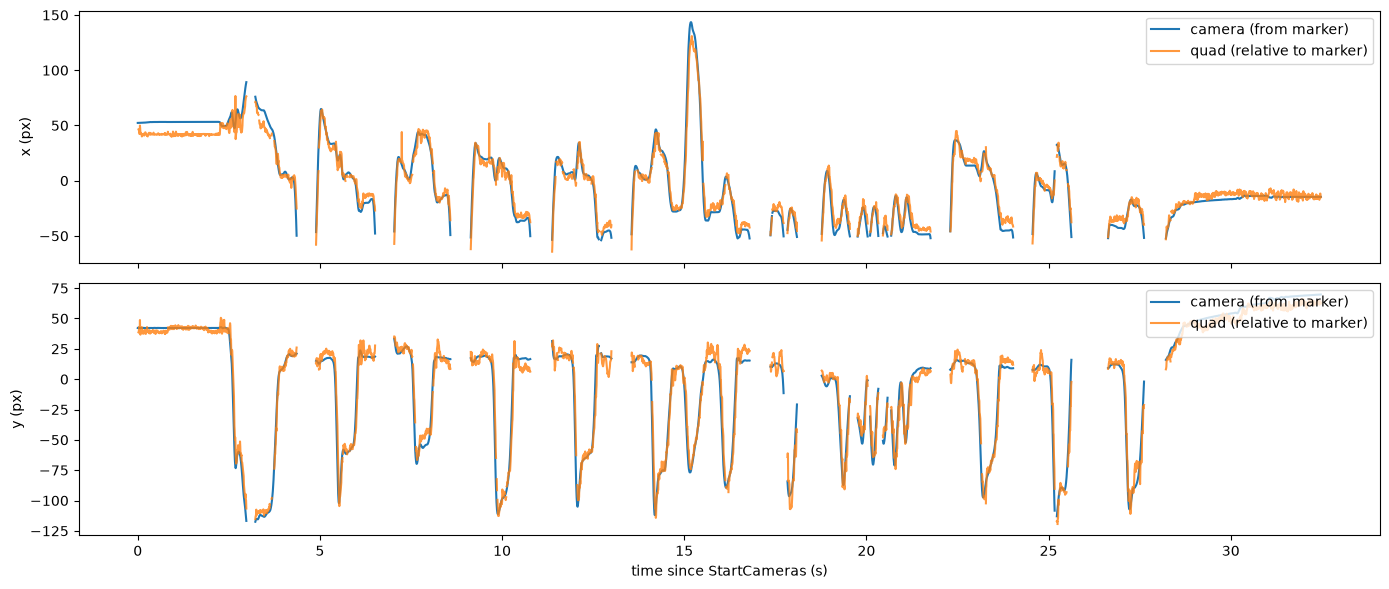

In [6]:
camera = pd.DataFrame({"x": -tracks["marker_x"], "y": -tracks["marker_y"]})
quad = pd.DataFrame({"x": tracks["quad_x"] - tracks["marker_x"], "y": tracks["quad_y"] - tracks["marker_y"]})
both = camera.notna().all(axis=1) & quad.notna().all(axis=1)
print(f"{both.sum()} frames with both marker and quad")

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, axis in zip(axes, ["x", "y"]):
    ax.plot(seconds, camera[axis] - camera[axis][both].mean(), label="camera (from marker)")
    ax.plot(seconds, quad[axis] - quad[axis][both].mean(), label="quad (relative to marker)", alpha=0.8)
    ax.set_ylabel(f"{axis} (px)")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("time since StartCameras (s)")
plt.tight_layout()

## Lag scan

For each candidate lag `L`, the camera trajectory is delayed by `L` (linear interpolation between frames, without
bridging gaps where the marker was not visible) and the RMS residual between the quad trajectory and the delayed
camera trajectory is computed, after removing the constant offset. The latency is the lag with the smallest residual.

{'x': '18 ms', 'y': '21 ms', 'x and y': '21 ms'}


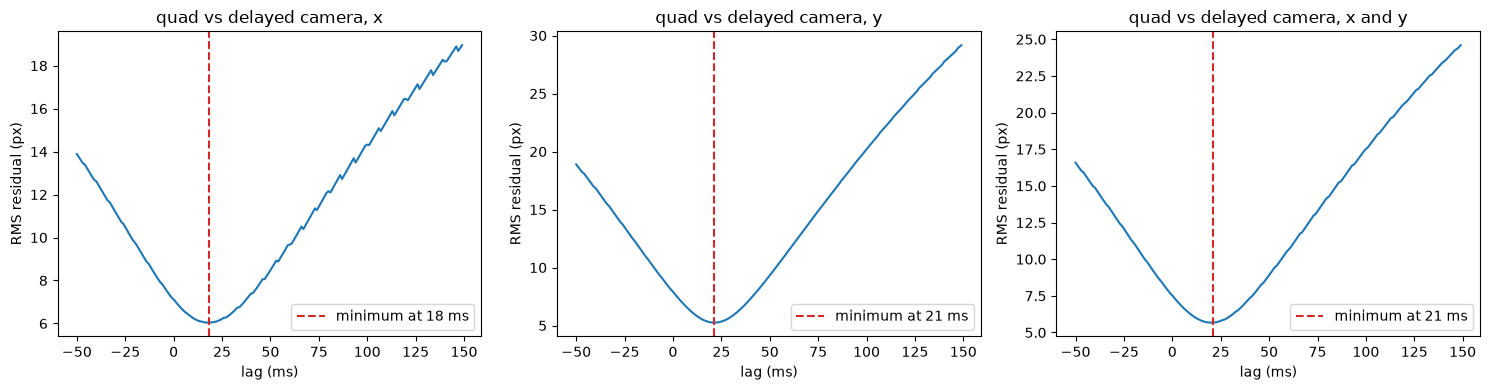

In [7]:
def delayed(series, lag):
    """`series` evaluated at `seconds - lag`, NaN where the series is missing or interpolation would bridge a gap."""
    valid = series.notna().values
    t_valid = seconds[valid]
    values = np.interp(seconds - lag, t_valid, series.values[valid], left=np.nan, right=np.nan)
    i = np.clip(np.searchsorted(t_valid, seconds - lag), 1, len(t_valid) - 1)
    values[(t_valid[i] - t_valid[i - 1]) > 2 * frame_interval] = np.nan
    return values


def lag_scan(signal, reference, lags, min_frames=100):
    """RMS residual of `signal(t) - reference(t - lag)` (mean offset removed) for each lag."""
    rms = np.full(len(lags), np.nan)
    for k, lag in enumerate(lags):
        residual = signal.values - delayed(reference, lag)
        residual = residual[~np.isnan(residual)]
        if len(residual) >= min_frames:
            rms[k] = np.sqrt(np.mean((residual - residual.mean()) ** 2))
    return rms


lags = np.arange(-0.05, 0.15, 0.001)
rms = {axis: lag_scan(quad[axis], camera[axis], lags) for axis in ["x", "y"]}
rms["x and y"] = np.sqrt((rms["x"] ** 2 + rms["y"] ** 2) / 2)
latency = {name: lags[np.nanargmin(r)] for name, r in rms.items()}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, r) in zip(axes, rms.items()):
    ax.plot(lags * 1e3, r)
    ax.axvline(latency[name] * 1e3, color="C3", linestyle="--", label=f"minimum at {latency[name] * 1e3:.0f} ms")
    ax.set_xlabel("lag (ms)")
    ax.set_ylabel("RMS residual (px)")
    ax.set_title(f"quad vs delayed camera, {name}")
    ax.legend()
plt.tight_layout()
print({name: f"{value * 1e3:.0f} ms" for name, value in latency.items()})

## Quad versus delayed camera

The segment of the session with the most camera motion, with the camera trajectory delayed by the estimated latency
overlaid on the quad trajectory.

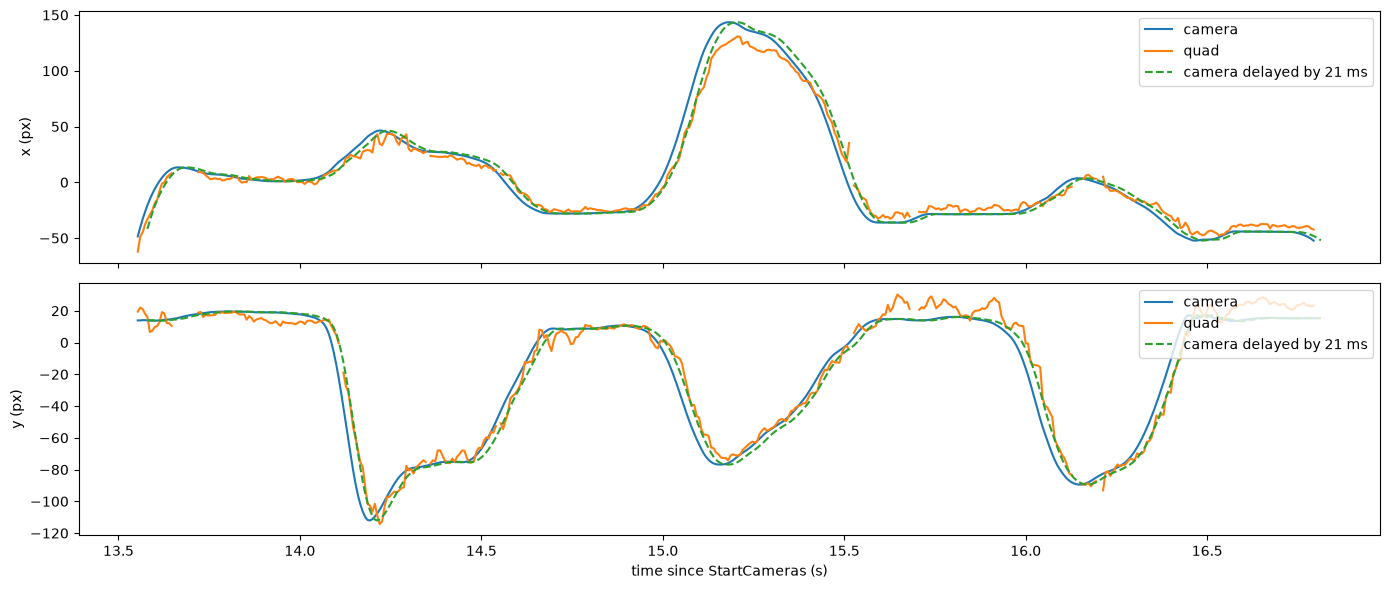

In [8]:
best = latency["x and y"]
speed = np.sqrt(camera["x"].diff() ** 2 + camera["y"].diff() ** 2)
centre = int(np.nanargmax(speed.rolling(150, center=True).mean().values))
window = slice(max(centre - 300, 0), centre + 300)

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, axis in zip(axes, ["x", "y"]):
    c = camera[axis] - camera[axis][both].mean()
    q = quad[axis] - quad[axis][both].mean()
    ax.plot(seconds[window], c.values[window], label="camera")
    ax.plot(seconds[window], q.values[window], label="quad")
    ax.plot(seconds[window], delayed(c, best)[window], "--", label=f"camera delayed by {best * 1e3:.0f} ms")
    ax.set_ylabel(f"{axis} (px)")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("time since StartCameras (s)")
plt.tight_layout()

## Consistency across the session

The lag scan is repeated on consecutive segments of the session to see how stable the estimate is. Segments with
too little marker visibility or too little camera motion (standard deviation of the camera position below
`min_motion`) are skipped, since without motion the lag is unconstrained. As an independent check, the frame-to-frame velocities of the quad and
the camera are cross-correlated: the peak should fall at the same lag, quantised to whole frames.

In [9]:
segment_length = 5.0
min_motion = 10.0  # px; segments where the camera barely moves cannot constrain the lag
segments = []
for start in np.arange(0, seconds[-1], segment_length):
    m = (seconds >= start) & (seconds < start + segment_length)
    motion = np.sqrt(camera["x"][m & both].var() + camera["y"][m & both].var())
    if (both & m).sum() < 150 or motion < min_motion:
        continue
    sub_seconds = seconds[m]
    sub_quad, sub_camera = quad[m].reset_index(drop=True), camera[m].reset_index(drop=True)

    def sub_scan(axis):
        valid = sub_camera[axis].notna().values
        t_valid = sub_seconds[valid]
        out = np.full(len(lags), np.nan)
        for k, lag in enumerate(lags):
            ref = np.interp(sub_seconds - lag, t_valid, sub_camera[axis].values[valid], left=np.nan, right=np.nan)
            i = np.clip(np.searchsorted(t_valid, sub_seconds - lag), 1, len(t_valid) - 1)
            ref[(t_valid[i] - t_valid[i - 1]) > 2 * frame_interval] = np.nan
            residual = sub_quad[axis].values - ref
            residual = residual[~np.isnan(residual)]
            if len(residual) >= 100:
                out[k] = np.sqrt(np.mean((residual - residual.mean()) ** 2))
        return out

    r = np.sqrt((sub_scan("x") ** 2 + sub_scan("y") ** 2) / 2)
    if not np.all(np.isnan(r)):
        segments.append({"start (s)": start, "frames": int((both & m).sum()), "camera motion (px)": motion, "latency (ms)": lags[np.nanargmin(r)] * 1e3, "residual (px)": np.nanmin(r)})
segments = pd.DataFrame(segments)
print(f"segments: median {segments['latency (ms)'].median():.0f} ms, range {segments['latency (ms)'].min():.0f} to {segments['latency (ms)'].max():.0f} ms")
segments

segments: median 20 ms, range 19 to 21 ms


,start (s),frames,camera motion (px),latency (ms),residual (px)
0,0.0,618,57.918353,20.0,4.427361
1,5.0,558,46.623457,21.0,4.374065
2,10.0,542,50.440871,20.0,4.732987
3,15.0,508,61.760362,21.0,5.836810
4,20.0,535,42.372196,20.0,4.774711
5,25.0,487,56.405569,19.0,4.625442


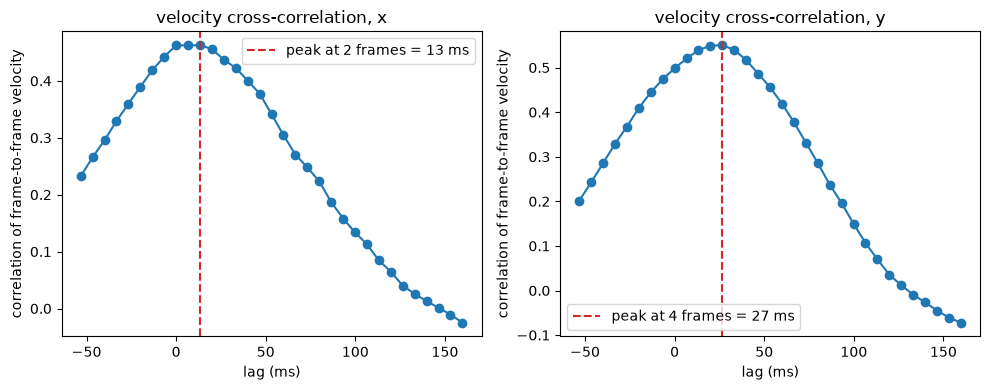

In [10]:
frame_lags = np.arange(-8, 25)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, axis in zip(axes, ["x", "y"]):
    v_quad, v_camera = quad[axis].diff(), camera[axis].diff()
    correlation = []
    for k in frame_lags:
        a, b = v_quad.values[max(k, 0):len(v_quad) + min(k, 0)], v_camera.shift(k).values[max(k, 0):len(v_quad) + min(k, 0)]
        valid = ~np.isnan(a) & ~np.isnan(b)
        correlation.append(np.corrcoef(a[valid], b[valid])[0, 1] if valid.sum() > 100 else np.nan)
    peak = frame_lags[np.nanargmax(correlation)]
    ax.plot(frame_lags * frame_interval * 1e3, correlation, "o-")
    ax.axvline(peak * frame_interval * 1e3, color="C3", linestyle="--", label=f"peak at {peak} frames = {peak * frame_interval * 1e3:.0f} ms")
    ax.set_xlabel("lag (ms)")
    ax.set_ylabel("correlation of frame-to-frame velocity")
    ax.set_title(f"velocity cross-correlation, {axis}")
    ax.legend()
plt.tight_layout()

## Interpretation

- The latency reported by the lag scan is the delay between the SubjectCamera's motion, as seen in its own frames,
  and the quad's motion on the screen, as seen in the same frames. It includes every stage of the loop and the
  display, but not the SubjectCamera's own exposure (both signals come from the same frames).
- The SubjectCamera samples at the trigger rate, so the raw time resolution is one frame interval; the lag scan
  interpolates between frames, which is why it resolves the minimum below one frame. The velocity cross-correlation
  is quantised to whole frames and is only a coarse check.
- The residual at the best lag is the tracking error that remains after accounting for latency: jitter and any
  scale mismatch of the loop, in SubjectCamera pixels on the screen plane.
- The screen renders with VSync off, so a frame can show the quad partly updated (tearing). Such frames bias the
  quad centroid towards the previous position by at most one quad height and are rare enough not to affect the lag.
- Quad size is not used: the session contains too little motion towards or away from the screen for the size
  signal to constrain the lag.